# Collecting Data

In [1]:
import getpass, os
os.environ["FIRMS_KEY"] = getpass.getpass("Masukkan MAP_KEY: ")

In [2]:
import requests
KEY = os.environ["FIRMS_KEY"]
r = requests.get("https://firms.modaps.eosdis.nasa.gov/mapserver/mapkey_status/", params={"MAP_KEY": KEY})
print(r.status_code)
print(r.text)

200
{ "transaction_limit" : 5000, "current_transactions": 0, "transaction_interval" : "10 minutes" }


In [3]:
r = requests.get(f"https://firms.modaps.eosdis.nasa.gov/api/data_availability/csv/{KEY}/ALL")
print(r.text[:1500])

data_id,min_date,max_date
MODIS_NRT,2026-08-01,2026-10-21
MODIS_SP,2000-11-01,2026-07-31
VIIRS_NOAA20_NRT,2026-07-01,2026-10-21
VIIRS_NOAA20_SP,2018-04-01,2026-06-30
VIIRS_NOAA21_NRT,2024-01-17,2026-10-20
VIIRS_NOAA21_SP,2023-03-01,2026-06-30
VIIRS_SNPP_NRT,2026-07-01,2026-10-20
VIIRS_SNPP_SP,2012-01-20,2026-06-30
LANDSAT_NRT,2022-06-20,2026-10-20
GOES_NRT,2022-08-09,2026-10-21
BA_MODIS,2000-11-01,2026-07-01
BA_VIIRS,2012-03-01,2026-07-01


In [ ]:
import os, io, time, requests, pandas as pd
from datetime import date, timedelta

KEY = os.environ["FIRMS_KEY"]
BBOX = "94,-11.5,141.5,6.5"        # seluruh Indonesia
OUT = "data/hotspot_raw"
os.makedirs(OUT, exist_ok=True)

KEEP = ["latitude","longitude","acq_date","acq_time","confidence","frp","bright_ti4","daynight","satellite"]

def tarik_5hari(source, start, n):
    u = f"https://firms.modaps.eosdis.nasa.gov/api/area/csv/{KEY}/{source}/{BBOX}/{n}/{start.isoformat()}"
    for coba in range(3):
        try:
            r = requests.get(u, timeout=120)
            if r.ok:
                if not r.text.strip() or r.text.lstrip().startswith("<"):
                    return pd.DataFrame()
                return pd.read_csv(io.StringIO(r.text))
        except requests.RequestException:
            pass
        time.sleep(5 * (coba + 1))
    raise RuntimeError(f"Gagal: {source} {start}")

def tarik_bulan(source, tahun, bulan, awal_global, akhir_global):
    path = f"{OUT}/{source}_{tahun}-{bulan:02d}.parquet"
    if os.path.exists(path):          # sudah ada, lewati
        return
    cur = max(date(tahun, bulan, 1), awal_global)
    akhir = date(tahun + (bulan == 12), bulan % 12 + 1, 1) - timedelta(days=1)
    akhir = min(akhir, akhir_global)
    bag = []
    while cur <= akhir:
        n = min(5, (akhir - cur).days + 1)
        d = tarik_5hari(source, cur, n)
        if len(d):
            bag.append(d[[c for c in KEEP if c in d.columns]])
        cur += timedelta(days=n)
        time.sleep(0.2)
    if bag:
        pd.concat(bag, ignore_index=True).to_parquet(path, index=False)
    print(source, tahun, bulan, sum(len(b) for b in bag))

def tarik_semua(source, mulai, selesai):
    y, m = mulai.year, mulai.month
    while date(y, m, 1) <= selesai:
        tarik_bulan(source, y, m, mulai, selesai)   # <- sekarang 5 argumen
        m += 1
        if m == 13:
            y, m = y + 1, 1

In [5]:
import os, io, zipfile, requests

URL = "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_IDN_1.json.zip"

if not os.path.exists("gadm41_IDN_1.json"):
    r = requests.get(URL, timeout=120)
    r.raise_for_status()
    zipfile.ZipFile(io.BytesIO(r.content)).extractall(".")

print(os.getcwd())
print(os.path.exists("gadm41_IDN_1.json"))

c:\Users\Lenovo\OneDrive - Politeknik Elektronika Negeri Surabaya\PENS ANJAY\SEMESTER 5\PROJEK SISTEM CERDAS\HotSpot
True


In [7]:
df_id = df[df["pulau"] != "Luar Indonesia"].copy()
print(f"{len(df_id):,} baris di dalam Indonesia")
df_id["pulau"].value_counts(normalize=True).mul(100).round(1)

1,825,700 baris di dalam Indonesia


pulau
Kalimantan              39.2
Sumatera                21.3
Maluku & Papua          13.8
Bali & Nusa Tenggara    11.6
Sulawesi                 8.0
Jawa                     6.0
Name: proportion, dtype: float64

In [16]:
def tarik_semua(source, mulai, selesai):
    y, m = mulai.year, mulai.month
    while date(y, m, 1) <= selesai:
        tarik_bulan(source, y, m, mulai, selesai)
        m += 1
        if m == 13:
            y, m = y + 1, 1

In [17]:
from datetime import date
tarik_semua("VIIRS_SNPP_SP", date(2012, 1, 20), date(2018, 3, 31))

VIIRS_SNPP_SP 2012 1 3632
VIIRS_SNPP_SP 2012 2 5914
VIIRS_SNPP_SP 2012 3 5919
VIIRS_SNPP_SP 2012 4 5876
VIIRS_SNPP_SP 2012 5 10453
VIIRS_SNPP_SP 2012 6 42945
VIIRS_SNPP_SP 2012 7 26188
VIIRS_SNPP_SP 2012 8 77379
VIIRS_SNPP_SP 2012 9 107915
VIIRS_SNPP_SP 2012 10 56277
VIIRS_SNPP_SP 2012 11 13999
VIIRS_SNPP_SP 2012 12 6293
VIIRS_SNPP_SP 2013 1 5838
VIIRS_SNPP_SP 2013 2 4521
VIIRS_SNPP_SP 2013 3 13680
VIIRS_SNPP_SP 2013 4 6691
VIIRS_SNPP_SP 2013 5 8007
VIIRS_SNPP_SP 2013 6 70982
VIIRS_SNPP_SP 2013 7 22013
VIIRS_SNPP_SP 2013 8 54495
VIIRS_SNPP_SP 2013 9 47387
VIIRS_SNPP_SP 2013 10 47104
VIIRS_SNPP_SP 2013 11 8380
VIIRS_SNPP_SP 2013 12 2263
VIIRS_SNPP_SP 2014 1 10005
VIIRS_SNPP_SP 2014 2 76544
VIIRS_SNPP_SP 2014 3 94615
VIIRS_SNPP_SP 2014 4 8517
VIIRS_SNPP_SP 2014 5 7991
VIIRS_SNPP_SP 2014 6 22582
VIIRS_SNPP_SP 2014 7 50469
VIIRS_SNPP_SP 2014 8 45394
VIIRS_SNPP_SP 2014 9 137063
VIIRS_SNPP_SP 2014 10 137864
VIIRS_SNPP_SP 2014 11 45383
VIIRS_SNPP_SP 2014 12 4244
VIIRS_SNPP_SP 2015 1 4537
VIIR

In [18]:
import glob, os
import pandas as pd

FOLDER = "data/hotspot_raw"
AKHIR = "2026-09"          # ganti ke "2026-10" kalau Oktober mau ikut

dipakai = []
for f in sorted(glob.glob(f"{FOLDER}/*.parquet")):
    nama = os.path.splitext(os.path.basename(f))[0]     # contoh: VIIRS_SNPP_SP_2012-01
    ym = nama.split("_")[-1]                            # contoh: 2012-01
    if ym > AKHIR:
        continue
    if "SNPP" in nama and ym >= "2018-04":              # buang file cek rasio 2019 (kalau ada)
        continue
    dipakai.append((f, nama))

for f, nama in dipakai:
    pd.read_parquet(f).to_csv(f"{FOLDER}/{nama}.csv", index=False)
    print("ok", nama)

print(len(dipakai), "file CSV (target: 177)")

ok VIIRS_NOAA20_NRT_2026-07
ok VIIRS_NOAA20_NRT_2026-08
ok VIIRS_NOAA20_NRT_2026-09
ok VIIRS_NOAA20_SP_2018-04
ok VIIRS_NOAA20_SP_2018-05
ok VIIRS_NOAA20_SP_2018-06
ok VIIRS_NOAA20_SP_2018-07
ok VIIRS_NOAA20_SP_2018-08
ok VIIRS_NOAA20_SP_2018-09
ok VIIRS_NOAA20_SP_2018-10
ok VIIRS_NOAA20_SP_2018-11
ok VIIRS_NOAA20_SP_2018-12
ok VIIRS_NOAA20_SP_2019-01
ok VIIRS_NOAA20_SP_2019-02
ok VIIRS_NOAA20_SP_2019-03
ok VIIRS_NOAA20_SP_2019-04
ok VIIRS_NOAA20_SP_2019-05
ok VIIRS_NOAA20_SP_2019-06
ok VIIRS_NOAA20_SP_2019-07
ok VIIRS_NOAA20_SP_2019-08
ok VIIRS_NOAA20_SP_2019-09
ok VIIRS_NOAA20_SP_2019-10
ok VIIRS_NOAA20_SP_2019-11
ok VIIRS_NOAA20_SP_2019-12
ok VIIRS_NOAA20_SP_2020-01
ok VIIRS_NOAA20_SP_2020-02
ok VIIRS_NOAA20_SP_2020-03
ok VIIRS_NOAA20_SP_2020-04
ok VIIRS_NOAA20_SP_2020-05
ok VIIRS_NOAA20_SP_2020-06
ok VIIRS_NOAA20_SP_2020-07
ok VIIRS_NOAA20_SP_2020-08
ok VIIRS_NOAA20_SP_2020-09
ok VIIRS_NOAA20_SP_2020-10
ok VIIRS_NOAA20_SP_2020-11
ok VIIRS_NOAA20_SP_2020-12
ok VIIRS_NOAA20_SP_2021-0

In [26]:
import glob, os
import pandas as pd
import geopandas as gpd

SRC = "data/hotspot_raw"
DST = "data/hotspot_indonesia"
OUT_FILE = "data/hotspot_indonesia_2012_2026-09.parquet"
AKHIR = "2026-09"
os.makedirs(DST, exist_ok=True)

# 1. Pilih file mentah yang dipakai
dipakai = []
for f in sorted(glob.glob(f"{SRC}/*.parquet")):
    nama = os.path.splitext(os.path.basename(f))[0]       # contoh: VIIRS_SNPP_SP_2012-01
    ym = nama.split("_")[-1]
    if ym > AKHIR:
        continue
    if "SNPP" in nama and ym >= "2018-04":                # buang file cek rasio 2019 (kalau ada)
        continue
    dipakai.append((f, nama))

print(len(dipakai), "file dipakai (target: 177)")
if not dipakai:
    raise FileNotFoundError(f"Tidak ada .parquet di {os.path.abspath(SRC)}")

# 2. Filter titik di dalam Indonesia, simpan per bulan
prov = gpd.read_file("gadm41_IDN_1.json")[["NAME_1", "geometry"]]

total_awal = total_akhir = 0
for f, nama in dipakai:
    d = pd.read_parquet(f)
    pts = gpd.GeoDataFrame(
        d,
        geometry=gpd.points_from_xy(d["longitude"], d["latitude"]),
        crs="EPSG:4326",
    )
    j = gpd.sjoin(pts, prov, how="inner", predicate="within")
    out = pd.DataFrame(j.drop(columns=["geometry", "index_right"], errors="ignore"))
    out = out.rename(columns={"NAME_1": "provinsi"})
    out = out[~out.index.duplicated()]
    out["produk"] = nama.rsplit("_", 1)[0]                # contoh: VIIRS_SNPP_SP
    out.to_parquet(f"{DST}/{nama}.parquet", index=False)
    total_awal += len(d)
    total_akhir += len(out)

print(f"{total_awal:,} -> {total_akhir:,} baris "
      f"({total_akhir / total_awal:.1%} di dalam Indonesia)")

# 3. Gabung jadi satu dataset parquet
df = pd.concat(
    (pd.read_parquet(f) for f in sorted(glob.glob(f"{DST}/*.parquet"))),
    ignore_index=True,
)
df["acq_date"] = pd.to_datetime(df["acq_date"])

print(df["satellite"].astype(str).value_counts())         # lihat kode asli sebelum dipetakan
df["satellite"] = df["satellite"].astype(str).map(
    {"N": "SNPP", "1": "NOAA20", "N20": "NOAA20"}
)
print("Satelit belum terpetakan:", df["satellite"].isna().sum())

n0 = len(df)
df = df.drop_duplicates(["latitude", "longitude", "acq_date", "acq_time", "satellite"])
print("Duplikat dibuang:", n0 - len(df))
df = df.sort_values(["acq_date", "acq_time"]).reset_index(drop=True)

df.to_parquet(OUT_FILE, index=False)
print(f"{len(df):,} baris | {df['acq_date'].min():%d %b %Y} - {df['acq_date'].max():%d %b %Y}")
print(f"Ukuran file: {os.path.getsize(OUT_FILE) / 1e6:.0f} MB")

177 file dipakai (target: 177)
4,546,457 -> 3,941,039 baris (86.7% di dalam Indonesia)
satellite
N      2219766
N20    1721273
Name: count, dtype: int64
Satelit belum terpetakan: 0
Duplikat dibuang: 1
3,941,038 baris | 20 Jan 2012 - 30 Sep 2026
Ukuran file: 79 MB


In [21]:
import glob, os
import pandas as pd

SRC = "data/hotspot_indonesia"
OUT_FILE = "data/hotspot_indonesia_2012_2026-09.csv"     # di luar folder SRC agar tidak terbaca ganda

bagian = []
for f in sorted(glob.glob(f"{SRC}/*.csv")):
    d = pd.read_csv(f)
    nama = os.path.splitext(os.path.basename(f))[0]       # contoh: VIIRS_SNPP_SP_2012-01
    d["produk"] = nama.rsplit("_", 1)[0]                  # contoh: VIIRS_SNPP_SP
    bagian.append(d)

df = pd.concat(bagian, ignore_index=True)

# seragamkan kode satelit (SNPP: N, NOAA-20: 1 atau N20)
df["satellite"] = df["satellite"].astype(str).map(
    {"N": "SNPP", "1": "NOAA20", "N20": "NOAA20"}
)
print("Satelit belum terpetakan:", df["satellite"].isna().sum())

# rapikan: buang duplikat, urutkan berdasarkan waktu
n0 = len(df)
df = df.drop_duplicates(["latitude", "longitude", "acq_date", "acq_time", "satellite"])
print("Duplikat dibuang:", n0 - len(df))
df = df.sort_values(["acq_date", "acq_time"]).reset_index(drop=True)

df.to_csv(OUT_FILE, index=False)

# ringkasan cepat
print(f"{len(df):,} baris | {len(bagian)} file | {df['acq_date'].min()} s/d {df['acq_date'].max()}")
print("Total null:", int(df.isna().sum().sum()))
print(df["satellite"].value_counts())
print(df.groupby(df["acq_date"].str[:4]).size())          # jumlah per tahun
print(f"Ukuran file: {os.path.getsize(OUT_FILE) / 1e6:.0f} MB")

Satelit belum terpetakan: 0
Duplikat dibuang: 1
3,941,038 baris | 177 file | 2012-01-20 s/d 2026-09-30
Total null: 0
satellite
SNPP      2219766
NOAA20    1721272
Name: count, dtype: int64
acq_date
2012    317705
2013    256871
2014    551669
2015    874521
2016    116629
2017     90433
2018    192281
2019    436391
2020     92814
2021     70654
2022     63365
2023    249838
2024    115609
2025     94026
2026    418232
dtype: int64
Ukuran file: 335 MB


# EDA 

1,048,575 baris | 20 Jan 2012 - 18 Oct 2014 | 11 kolom
Total null: 0
Kolom: latitude, longitude, acq_date, acq_time, confidence, frp, bright_ti4, daynight, satellite, provinsi, produk
confidence
n    953002
l     59483
h     36090
Name: count, dtype: int64
produk
VIIRS_SNPP_SP    1048575
Name: count, dtype: int64
acq_date
2012    317705
2013    256871
2014    473999
dtype: int64
pulau
Sumatera                48.1
Kalimantan              31.9
Bali & Nusa Tenggara     6.7
Maluku & Papua           5.5
Sulawesi                 4.5
Jawa                     3.4
Name: proportion, dtype: float64
Provinsi tak terpetakan: []


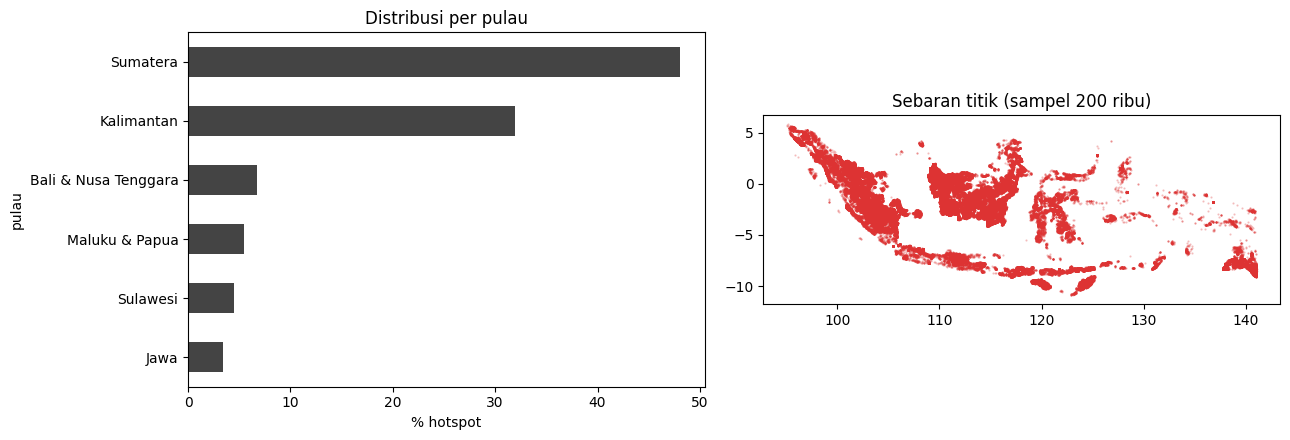

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Baca dataset gabungan
df = pd.read_csv("data/hotspot_indonesia_2012_2026-09.csv", parse_dates=["acq_date"])

# 2. Angka utama (bahan slide)
print(f"{len(df):,} baris | "
      f"{df['acq_date'].min():%d %b %Y} - {df['acq_date'].max():%d %b %Y} | "
      f"{df.shape[1]} kolom")
print("Total null:", int(df.isna().sum().sum()))
print("Kolom:", ", ".join(df.columns))
print(df["confidence"].value_counts())
print(df["produk"].value_counts())
print(df.groupby(df["acq_date"].dt.year).size())      # cek 2015 melonjak

# 3. Provinsi -> pulau (provinsi sudah ada dari langkah filter)
PULAU = {
    "Sumatera": ["aceh", "sumatera", "riau", "jambi", "bengkulu", "lampung", "bangka"],
    "Jawa": ["jawa", "banten", "jakarta", "yogyakarta"],
    "Kalimantan": ["kalimantan"],
    "Sulawesi": ["sulawesi", "gorontalo"],
    "Bali & Nusa Tenggara": ["bali", "nusatenggara"],
    "Maluku & Papua": ["maluku", "papua"],
}

def ke_pulau(p):
    if pd.isna(p):
        return "Lainnya"
    p = p.lower().replace(" ", "")
    for nama, kunci in PULAU.items():
        if any(k in p for k in kunci):
            return nama
    return "Lainnya"

df["pulau"] = df["provinsi"].map(ke_pulau)
dist = df["pulau"].value_counts(normalize=True).mul(100).round(1)
print(dist)
print("Provinsi tak terpetakan:", df.loc[df["pulau"] == "Lainnya", "provinsi"].unique())

# 4. Visual: bar per pulau + peta sebaran titik
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
dist.sort_values().plot.barh(ax=ax[0], color="#444")
ax[0].set_xlabel("% hotspot")
ax[0].set_title("Distribusi per pulau")

s = df.sample(200_000, random_state=42)
ax[1].scatter(s["longitude"], s["latitude"], s=0.3, alpha=0.3, c="#d33")
ax[1].set_aspect("equal")
ax[1].set_title("Sebaran titik (sampel 200 ribu)")

plt.tight_layout()
plt.savefig("gambaran_data.png", dpi=200)
plt.show()